In [ ]:
import pathlib
import random
import re
import warnings

import alifedata_phyloinformatics_convert as apc
from hstrat import _auxiliary_lib as hstrat_aux
import iplotx as ipx
import marimo as mo
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from phyloframe import legacy as pfl
import polars as pl
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from watermark import watermark

from pylib import osf_fetch, percentileofscore_grouped

warnings.filterwarnings("ignore", category=DeprecationWarning)

OSF_SLUGS = ("j4mxn", "nhkz9", "65ytg", "ma4rb")
NUM_SITES = 16
ALPHA = 0.05
MAX_TREE_LEAVES = 4000
SEED = 1

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/alifedata_phyloinformatics_convert/_impl/phytrack_Systematcs.py:7: UserWarning: ImportWarning: phylotrackpy.Systematics import failed; inserting a no-op mock for Systematics. This is likely because phylotrackpy is not installed.
  warnings.warn(


In [ ]:
mo.md(f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
""")

```Text
Last updated: 2026-10-26T12:57:39.916070+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 7.31.1

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 6.17.0-1022-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

phyloframe                        : 0.12.2
seaborn                           : 0.13.2
iplotx                            : 1.8.0
teeplot                           : 1.4.2
re                                : 2.2.1
numpy                             : 2.1.2
marimo                            : 0.23.2
polars                            : 1.36.1
scipy                             : 1.14.1
matplotlib                        : 3.10.9
pandas                            : 2.2.3
alifedata_phyloinformatics_convert: 0.19.3
hstrat                            : 1.25.2

```

In [ ]:
mo.md(f"""
# MLS Individual-host Rate-matched Reservoir Fossils: Detectability by Population Size and Effect Size

Applies the phylogeny-based multilevel selection (MLS) screen from *Extending a Phylogeny-based Method for Detecting Signatures of Multi-level Selection for Applications in Artificial Life* (ISAL 2025, <https://doi.org/10.1162/ISAL.a.916>; code at <https://github.com/mmore500/multilevel-selection-concept>) to wafer-scale evolution data, following `2026-10-18-mls-spectrum-subgrid-fossils`.

Data were generated by [`wse-async-ga` `wsclust/2026-10-19-mls-indiv-ratematched-fossils-reservoir`](https://github.com/mmore500/wse-async-ga/tree/master/wsclust/2026-10-19-mls-indiv-ratematched-fossils-reservoir) and are hosted at {", ".join(f"<https://osf.io/{slug}>" for slug in OSF_SLUGS)}.
Each file is one run's minified hstrat-reconstructed phylogeny (`05-minify-phylo` output), for subgrid sizes 0 (i.e., the full grid), 27, 81, and 243.
Fossils were collected by reservoir sampling, so each fossil layer spans the whole run rather than one timepoint.

Runs use genome flavor `genome_mlsindiv_2026_10_18`, in which each population member is an individual host: a clear genome is an uninfected host, and otherwise the genome is the host's (transmitted) consensus strain.
The genome carries eight MLS sites with base effect sizes $s_i \\in [1.0, 0.5, 0.25, 0.1, 0.05, 0.025, 0.01, 0.005]$, and eight neutral sites.
Each MLS site present blocks transmission with probability $s_i$ times a transmission reduction scale (0.5 here), but is gained within a host with probability equal to the mutant fraction after 25 within-host doublings with relative growth rate $1 + s_i$ (and lost with growth rate $1 / (1 + s_i)$).
Neutral sites flip at the rate-matched $s \\to 0$ limit of the same rule, so weak MLS sites converge to the neutral flip rate.
Runs sweep subgrid size, where subgrids are blocks of tiles between which migration is disabled.

Each subgrid is an isolated metapopulation, so populations are analyzed independently rather than pooled: within each population, the screen asks whether each MLS site

1. gives rise to more mutation-defined clades (MDCs) than expected for a neutral site (mutation-frequency screen), and
2. gives rise to MDCs that are smaller and/or shorter-lived than neutral-site MDCs (clade-fitness screen).

Detectability is the fraction of populations in which a screen is significant at $\\alpha = {ALPHA}$, broken down by population size and effect size.
As a null calibration, the same screens are applied to each of the eight neutral sites, against the other neutral sites.
""")

# MLS Individual-host Rate-matched Reservoir Fossils: Detectability by Population Size and Effect Size

Applies the phylogeny-based multilevel selection (MLS) screen from *Extending a Phylogeny-based Method for Detecting Signatures of Multi-level Selection for Applications in Artificial Life* (ISAL 2025, <https://doi.org/10.1162/ISAL.a.916>; code at <https://github.com/mmore500/multilevel-selection-concept>) to wafer-scale evolution data, following `2026-10-18-mls-spectrum-subgrid-fossils`.

Data were generated by [`wse-async-ga` `wsclust/2026-10-19-mls-indiv-ratematched-fossils-reservoir`](https://github.com/mmore500/wse-async-ga/tree/master/wsclust/2026-10-19-mls-indiv-ratematched-fossils-reservoir) and are hosted at <https://osf.io/j4mxn>, <https://osf.io/nhkz9>, <https://osf.io/65ytg>, <https://osf.io/ma4rb>.
Each file is one run's minified hstrat-reconstructed phylogeny (`05-minify-phylo` output), for subgrid sizes 0 (i.e., the full grid), 27, 81, and 243.
Fossils were collected by reservoir sampling, so each fossil layer spans the whole run rather than one timepoint.

Runs use genome flavor `genome_mlsindiv_2026_10_18`, in which each population member is an individual host: a clear genome is an uninfected host, and otherwise the genome is the host's (transmitted) consensus strain.
The genome carries eight MLS sites with base effect sizes $s_i \in [1.0, 0.5, 0.25, 0.1, 0.05, 0.025, 0.01, 0.005]$, and eight neutral sites.
Each MLS site present blocks transmission with probability $s_i$ times a transmission reduction scale (0.5 here), but is gained within a host with probability equal to the mutant fraction after 25 within-host doublings with relative growth rate $1 + s_i$ (and lost with growth rate $1 / (1 + s_i)$).
Neutral sites flip at the rate-matched $s \to 0$ limit of the same rule, so weak MLS sites converge to the neutral flip rate.
Runs sweep subgrid size, where subgrids are blocks of tiles between which migration is disabled.

Each subgrid is an isolated metapopulation, so populations are analyzed independently rather than pooled: within each population, the screen asks whether each MLS site

1. gives rise to more mutation-defined clades (MDCs) than expected for a neutral site (mutation-frequency screen), and
2. gives rise to MDCs that are smaller and/or shorter-lived than neutral-site MDCs (clade-fitness screen).

Detectability is the fraction of populations in which a screen is significant at $\alpha = 0.05$, broken down by population size and effect size.
As a null calibration, the same screens are applied to each of the eight neutral sites, against the other neutral sites.

## Get Data

In [ ]:
data_paths = [osf_fetch(slug) for slug in OSF_SLUGS]

downloading https://osf.io/j4mxn/download -> /tmp/j4mxn
size: 47275519 bytes
downloading https://osf.io/nhkz9/download -> /tmp/nhkz9
size: 45897132 bytes
downloading https://osf.io/65ytg/download -> /tmp/65ytg
size: 46642342 bytes
downloading https://osf.io/ma4rb/download -> /tmp/ma4rb
size: 46994115 bytes


In [ ]:
pl.scan_parquet(data_paths[0]).collect_schema()

Schema([('origin_time', Int16), ('dstream_rank', Int16), ('dstream_S', Int16), ('hstrat_differentia_bitwidth', UInt8), ('is_extant', Boolean), ('trait_focal', UInt16), ('layer', UInt8), ('layer_T', UInt8), ('row', UInt16), ('col', UInt16), ('subgrid', UInt8), ('subgrid_row', UInt8), ('subgrid_col', UInt8), ('config', String), ('file', Categorical), ('replicate', Categorical), ('sample_per_stratum', UInt16), ('genomeFlavor', Categorical), ('populationFlavor', Categorical), ('memcpyMajor', Categorical), ('globalSeed', UInt8), ('nCol', UInt16), ('nRow', UInt16), ('nWav', UInt8), ('nTrait', UInt8), ('nCycle', UInt16), ('nColSubgrid', UInt8), ('nRowSubgrid', UInt8), ('nonBlock', Boolean), ('tilePopSize', UInt16), ('tournSize', Float32), ('msec', Float32), ('tsc', UInt8), ('dstream_algo', Categorical), ('dstream_storage_bitoffset', UInt8), ('dstream_storage_bitwidth', UInt8), ('dstream_T_bitoffset', UInt8), ('dstream_T_bitwidth', UInt8), ('dstream_S_right', UInt8), ('flag_site_bitwidth', UInt8), ('flag_sites_bitoffset', UInt8), ('flag_sites_bitwidth', UInt8), ('mls_transmission_reduction_p_byte1_bit0', Float32), ('mls_withinhost_gain_p_byte1_bit0', Float32), ('mls_withinhost_loss_p_byte1_bit0', Float32), ('mls_transmission_reduction_p_byte1_bit1', Float32), ('mls_withinhost_gain_p_byte1_bit1', Float32), ('mls_withinhost_loss_p_byte1_bit1', Float32), ('mls_transmission_reduction_p_byte1_bit2', Float32), ('mls_withinhost_gain_p_byte1_bit2', Float32), ('mls_withinhost_loss_p_byte1_bit2', Float32), ('mls_transmission_reduction_p_byte1_bit3', Float32), ('mls_withinhost_gain_p_byte1_bit3', Float32), ('mls_withinhost_loss_p_byte1_bit3', Float32), ('mls_transmission_reduction_p_byte1_bit4', Float32), ('mls_withinhost_gain_p_byte1_bit4', Float32), ('mls_withinhost_loss_p_byte1_bit4', Float32), ('mls_transmission_reduction_p_byte1_bit5', Float32), ('mls_withinhost_gain_p_byte1_bit5', Float32), ('mls_withinhost_loss_p_byte1_bit5', Float32), ('mls_transmission_reduction_p_byte1_bit6', Float32), ('mls_withinhost_gain_p_byte1_bit6', Float32), ('mls_withinhost_loss_p_byte1_bit6', Float32), ('mls_transmission_reduction_p_byte1_bit7', Float32), ('mls_withinhost_gain_p_byte1_bit7', Float32), ('mls_withinhost_loss_p_byte1_bit7', Float32), ('mls_host_clear_p', Float32), ('mls_withinhost_neutral_p', Float32), ('_compconf_dummy', UInt8), ('CEREBRASLIB_TRAITLOGGER_NUM_BITS', UInt8), ('CEREBRASLIB_NONZERO_FIT_FUDGE', Float32), ('CEREBRASLIB_POPULATION_EXTINCTION_PROBABILITY', Float32), ('CEREBRASLIB_MLS_TRANSMISSION_REDUCTION_SCALE', Float32), ('CEREBRASLIB_MLS_WITHINHOST_DOUBLINGS', Float32), ('CEREBRASLIB_TRAITLOGGER_DILATION', UInt8), ('CEREBRASLIB_TRAITLOGGER_DSTREAM_ALGO_NAME', Categorical), ('CEREBRASLIB_HSTRAT_T_DILATION', UInt8), ('CEREBRASLIB_HSTRAT_DSTREAM_ALGO_NAME', Categorical), ('CEREBRASLIB_MLS_LOG10_NEUTRAL_MUTATION_RATE', Float32), ('CEREBRASLIB_MLS_HOST_CLEAR_P', Float32), ('ASYNC_GA_FOSSIL_SAMPLING_MODE', Categorical), ('ASYNC_GA_GENOME_FLAVOR', Categorical), ('ASYNC_GA_POPULATION_FLAVOR', Categorical), ('ASYNC_GA_POPSIZE', UInt16), ('clade_size', UInt8), ('last_origin_time', Int16), ('trait_present', UInt16), ('ancestor_offset', Int16)])

In [ ]:
def _config_cols(names):
    return [
        name
        for name in names
        if name.startswith(("ASYNC_GA_", "CEREBRASLIB_", "dstream_algo"))
        or re.match(r"^mls_.*$", name)
        or name
        in (
            "config",
            "genomeFlavor",
            "populationFlavor",
            "globalSeed",
            "nCol",
            "nRow",
            "nColSubgrid",
            "nRowSubgrid",
            "nWav",
            "nTrait",
            "nCycle",
            "tilePopSize",
            "tournSize",
            "replicate",
            "trait_focal",
            "dstream_S",
            "hstrat_differentia_bitwidth",
        )
    ]

_rows = []
for _path in data_paths:
    _lazy = pl.scan_parquet(_path).filter(pl.col("clade_size") > 0)
    # each file holds one run; check before taking its first row
    assert _lazy.select(pl.col("config").n_unique()).collect().item() == 1
    _rows.append(
        _lazy.select(_config_cols(_lazy.collect_schema().names()))
        .head(1)
        .collect()
    )
config_df = pl.concat(_rows, how="diagonal_relaxed").sort("nRowSubgrid")
assert config_df["config"].is_unique().all(), "expected one row per run"
assert (config_df["nRowSubgrid"] == config_df["nColSubgrid"]).all()
config_df.transpose(include_header=True)

column,column_0,column_1,column_2,column_3
str,str,str,str,str
"""dstream_S""","""128""","""128""","""128""","""128"""
"""hstrat_differentia_bitwidth""","""1""","""1""","""1""","""1"""
"""trait_focal""","""65280""","""65280""","""65280""","""65280"""
"""config""","""flavor=genome_mlsindiv_2026_10…","""flavor=genome_mlsindiv_2026_10…","""flavor=genome_mlsindiv_2026_10…","""flavor=genome_mlsindiv_2026_10…"
"""replicate""","""38a6a0b6-991a-4e31-9163-1156d5…","""90c333d9-8742-4805-b4ab-5c8b9b…","""aaabb6a4-11d3-41bb-bcd8-f7068b…","""b6d8ed81-793e-4f8a-ba90-27cacb…"
…,…,…,…,…
"""CEREBRASLIB_MLS_HOST_CLEAR_P""","""0.1""","""0.1""","""0.1""","""0.1"""
"""ASYNC_GA_FOSSIL_SAMPLING_MODE""","""reservoir""","""reservoir""","""reservoir""","""reservoir"""
"""ASYNC_GA_GENOME_FLAVOR""","""genome_mlsindiv_2026_10_18""","""genome_mlsindiv_2026_10_18""","""genome_mlsindiv_2026_10_18""","""genome_mlsindiv_2026_10_18"""


In [ ]:
# MLS site i is flag byte B, bit b (trait site 8B + b); its transmission
# reduction is base effect size s_i times the transmission reduction scale
_site_cols = [
    (int(B) * 8 + int(b), what, col)
    for col in config_df.columns
    for what, B, b in re.findall(
        r"^mls_(transmission_reduction|withinhost_gain|withinhost_loss)"
        r"_p_byte(\d+)_bit(\d+)$",
        col,
    )
]
effect_sizes = (
    pd.DataFrame(
        [
            {
                "config": row["config"],
                "site": site,
                f"{what}_p": row[col],
                "txscale": row[
                    "CEREBRASLIB_MLS_TRANSMISSION_REDUCTION_SCALE"
                ],
            }
            for row in config_df.iter_rows(named=True)
            for site, what, col in _site_cols
        ],
    )
    .groupby(["config", "site"], as_index=False)
    .first()
)
effect_sizes["effect_size"] = (
    effect_sizes["transmission_reduction_p"] / effect_sizes["txscale"]
).round(6)
# effect sizes are the same across runs
assert (effect_sizes.groupby("site")["effect_size"].nunique() == 1).all()
focal_sites = sorted(effect_sizes["site"].unique().tolist())
_focal_mask = sum(1 << site for site in focal_sites)
assert (config_df["trait_focal"] == _focal_mask).all(), "focal mismatch"
background_sites = [
    site for site in range(NUM_SITES) if site not in focal_sites
]
# every neutral site serves as a null control, against the others
control_sites = background_sites
site_effect_sizes = effect_sizes.groupby("site")["effect_size"].first()
effect_sizes

,config,site,transmission_reduction_p,txscale,withinhost_gain_p,withinhost_loss_p,effect_size
0,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,8,0.5000,0.5,0.999653,7.999969e-08,1.000
1,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,9,0.2500,0.5,0.021016,1.199711e-07,0.500
2,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,10,0.1250,0.5,0.000083,1.986524e-07,0.250
3,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,11,0.0500,0.5,0.000004,3.946663e-07,0.100
4,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,12,0.0250,0.5,0.000002,5.845754e-07,0.050
...,...,...,...,...,...,...,...
27,flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3,11,0.0500,0.5,0.000004,3.946663e-07,0.100
28,flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3,12,0.0250,0.5,0.000002,5.845754e-07,0.050
29,flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3,13,0.0125,0.5,0.000001,7.486867e-07,0.025
30,flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3,14,0.0050,0.5,0.000001,8.858464e-07,0.010


## Prep Data

Minification collapsed each maximal clade of genomes sharing identical traits onto its root, which became a leaf; `clade_size` gives the number of fossil genomes it represents, and `last_origin_time` the latest among them.
Genome counts below weight leaves by `clade_size`.

Fossil layer 0 samples the initial population, at `origin_time == -1` before any lineage history accumulated (as in `2026-10-15-mls-strong-fossils`), so these genomes are dropped (collapsed leaves are kept if any member has `last_origin_time >= 0`).
Some roots have no `origin_time`; as roots can be no later than the run start, it is set to -1.
Lineages without retained leaves are pruned and unifurcations collapsed.

In [ ]:
# runs are independent, so each run's file is loaded, checked, summarized,
# and pruned separately to bound memory use
_pruned, _tips, _site_freqs, _times = [], [], [], []
_offset = 0
for _path in data_paths:
    # unminify: rows are in depth-first order, with id = row index
    _raw = (
        pl.read_parquet(
            _path,
            columns=[
                "ancestor_offset",
                "origin_time",
                "last_origin_time",
                "clade_size",
                "trait_present",
                "config",
                "layer",
                "subgrid",
            ],
        )
        .with_row_index("id")
        .with_columns(
            pl.col("id").cast(pl.Int64),
            ancestor_id=(
                pl.col("id").cast(pl.Int64)
                - pl.col("ancestor_offset").cast(pl.Int64)
            ),
            config=pl.col("config").cast(pl.String),
            # the full-grid run also fills subgrid (0) on inner nodes
            subgrid=pl.when(pl.col("clade_size") > 0).then(
                pl.col("subgrid").cast(pl.Int64)
            ),
            trait_present=pl.col("trait_present").cast(pl.Int64),
        )
        .drop("ancestor_offset")
        .to_pandas()
    )

    # some roots lack origin_time; roots can be no later than run start
    _no_time = _raw["origin_time"].isna()
    assert (
        _raw.loc[_no_time, "ancestor_id"] == _raw.loc[_no_time, "id"]
    ).all()
    _raw["origin_time"] = _raw["origin_time"].fillna(-1)
    _raw["last_origin_time"] = _raw["last_origin_time"].fillna(
        _raw["origin_time"]
    )

    _is_genome = _raw["clade_size"] > 0
    assert (_is_genome == _raw["trait_present"].notna()).all()
    assert (_is_genome == _raw["subgrid"].notna()).all()
    assert _raw["config"].notna().all()
    assert (_raw["ancestor_id"] <= _raw["id"]).all()
    _has_child = np.zeros(len(_raw), dtype=bool)
    _has_child[_raw["ancestor_id"]] = True
    _has_child[_raw["ancestor_id"] == _raw["id"]] = False
    # collapsed monomorphic clades and fossil genomes are leaves
    assert not (_has_child & _is_genome).any()

    _tips.append(
        _raw[_is_genome]
        .groupby("config")
        .agg(
            num_leaves=("id", "size"),
            num_genomes=("clade_size", "sum"),
            clade_size_mean=("clade_size", "mean"),
            clade_size_max=("clade_size", "max"),
            num_layers=("layer", "nunique"),
            origin_time_min=("origin_time", "min"),
            last_origin_time_max=("last_origin_time", "max"),
            negative_origin_frac=(
                "last_origin_time",
                lambda x: (x < 0).mean(),
            ),
        )
        .assign(num_nodes=len(_raw)),
    )
    _times.append(
        _raw.assign(is_genome=_is_genome)
        .groupby(["config", "is_genome"])[
            ["origin_time", "last_origin_time"]
        ]
        .describe(),
    )

    _extant = _is_genome & (_raw["last_origin_time"] >= 0)
    _weights = _raw.loc[_extant, "clade_size"].to_numpy(dtype=float)
    _present = _raw.loc[_extant, "trait_present"].to_numpy(dtype=np.uint64)
    _site_freqs.append(
        pd.Series(
            {
                f"site {site}"
                + (
                    f" (s={site_effect_sizes[site]:g})"
                    if site in focal_sites
                    else " (neutral)"
                ): (
                    ((_present >> np.uint64(site)) & np.uint64(1))
                    * _weights
                ).sum()
                / _weights.sum()
                for site in range(NUM_SITES)
            },
            name=_raw["config"].iloc[0],
        ),
    )

    _part = (
        _raw.assign(extant=_extant)
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_prune_extinct_lineages_asexual, mutate=True)
        .pipe(pfl.alifestd_collapse_unifurcations, mutate=True)
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_mark_leaves, mutate=True)
        .reset_index(drop=True)
    )
    del _raw
    assert (_part["is_leaf"] == _part["extant"]).all()
    _part = _part.drop(columns=["extant", "layer"])
    # offset ids so they are unique across runs
    _part["id"] += _offset
    _part["ancestor_id"] += _offset
    _offset += len(_part)
    _pruned.append(_part)
    del _part

phylo_pruned = pd.concat(_pruned, ignore_index=True)
del _pruned
assert (phylo_pruned["id"] == np.arange(len(phylo_pruned))).all()
tips_summary = pd.concat(_tips).T
times_summary = pd.concat(_times).T
# genome-weighted fraction of fossil genomes carrying each site, by run
site_frequencies = pd.DataFrame(_site_freqs).T
phylo_pruned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23267889 entries, 0 to 23267888
Data columns (total 9 columns):
 #   Column            Dtype  
---  ------            -----  
 0   id                int64  
 1   origin_time       float64
 2   last_origin_time  float64
 3   clade_size        uint8  
 4   trait_present     float64
 5   config            object 
 6   subgrid           float64
 7   ancestor_id       int64  
 8   is_leaf           bool   
dtypes: bool(1), float64(4), int64(2), object(1), uint8(1)
memory usage: 1.3+ GB


In [ ]:
tips_summary

config,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,flavor=genome_mlsindiv_2026_10_18+subgrid=27+txscale=0.5+seed=2,flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3,flavor=genome_mlsindiv_2026_10_18+subgrid=243+txscale=0.5+seed=4
num_leaves,3.055393e+06,3.027352e+06,3.038468e+06,3.062575e+06
num_genomes,3.999960e+06,3.991680e+06,3.993750e+06,3.998880e+06
clade_size_mean,1.309147e+00,1.318538e+00,1.314396e+00,1.305725e+00
clade_size_max,2.500000e+01,2.100000e+01,2.500000e+01,2.600000e+01
num_layers,7.200000e+01,7.200000e+01,7.100000e+01,7.200000e+01
origin_time_min,-1.000000e+00,-1.000000e+00,-1.000000e+00,-1.000000e+00
last_origin_time_max,7.805000e+03,7.853000e+03,7.793000e+03,7.825000e+03
negative_origin_frac,1.813646e-02,1.831303e-02,1.851196e-02,1.813376e-02
num_nodes,5.957763e+06,5.751003e+06,5.854987e+06,5.926774e+06


In [ ]:
times_summary

config flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1 flavor=genome_mlsindiv_2026_10_18+subgrid=27+txscale=0.5+seed=2 flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3 flavor=genome_mlsindiv_2026_10_18+subgrid=243+txscale=0.5+seed=4 is_genome False True False True False True False True origin_time count 2.902370e+06 3.055393e+06 2.723651e+06 3.027352e+06 2.816519e+06 3.038468e+06 2.864199e+06 3.062575e+06 mean 1.539040e+03 3.277406e+03 1.428237e+03 3.247145e+03 1.469518e+03 3.254084e+03 1.692677e+03 3.315676e+03 std 1.545704e+03 2.254655e+03 1.667275e+03 2.320595e+03 1.652948e+03 2.288619e+03 1.766824e+03 2.290325e+03 min -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 25% 3.500000e+02 1.313000e+03 1.270000e+02 1.182000e+03 1.900000e+02 1.214000e+03 2.860000e+02 1.278000e+03 ... ... ... ... ... ... ... ... ... ... last_origin_time min -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 25% 3.500000e+02 1.695000e+03 1.270000e+02 1.765000e+03 1.900000e+02 1.745000e+03 2.860000e+02 1.745000e+03 50% 1.022000e+03 3.787000e+03 6.380000e+02 3.847000e+03 7.660000e+02 3.823000e+03 9.590000e+02 3.821000e+03 75% 2.238000e+03 5.979000e+03 2.430000e+03 6.035000e+03 2.430000e+03 5.981000e+03 2.687000e+03 5.987000e+03 max 7.663000e+03 7.805000e+03 7.671000e+03 7.853000e+03 7.647000e+03 7.793000e+03 7.687000e+03 7.825000e+03 16 rows × 8 columns

In [ ]:
# render in full; marimo's default display truncates to ten rows
mo.Html(site_frequencies.to_html(float_format="{:.5f}".format))

,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,flavor=genome_mlsindiv_2026_10_18+subgrid=27+txscale=0.5+seed=2,flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3,flavor=genome_mlsindiv_2026_10_18+subgrid=243+txscale=0.5+seed=4
site 0 (neutral),0.00206,0.00214,0.00216,0.00216
site 1 (neutral),0.00215,0.00211,0.00210,0.00205
site 2 (neutral),0.00208,0.00214,0.00214,0.00210
site 3 (neutral),0.00210,0.00214,0.00204,0.00213
site 4 (neutral),0.00214,0.00214,0.00213,0.00219
site 5 (neutral),0.00212,0.00210,0.00214,0.00214
site 6 (neutral),0.00219,0.00217,0.00210,0.00223
site 7 (neutral),0.00209,0.00213,0.00213,0.00221
site 8 (s=1),1.00000,1.00000,1.00000,1.00000
site 9 (s=0.5),0.66610,0.66593,0.66560,0.66575


The s=1 MLS site is present in essentially all fossil genomes, and the s=0.5 site in about two thirds of them; weaker MLS sites are rarer than neutral sites.
Parsimony places the gain of a near-fixed trait at tree roots, which are not counted as MDCs, so the screens have little to work with for the s=1 site.

## Split Populations

Subgrids share no migration, so no true common ancestry links genomes from different subgrids (or runs); each run's tree was reconstructed independently, but hstrat reconstruction can still join unrelated lineages at spurious deep nodes.
To analyze each population (run × subgrid) independently, nodes whose descendant leaves span more than one population are deleted, making each maximal single-population clade a root.
Each population's forest is then analyzed separately.

Edge subgrids are truncated by the grid boundary (e.g., 755 columns is not a multiple of 27), so only full-size subgrids are retained.

In [ ]:
_config_codes = {
    config: i for i, config in enumerate(config_df["config"].to_list())
}
_is_leaf = phylo_pruned["is_leaf"].to_numpy()
_pop_code = np.where(
    _is_leaf,
    phylo_pruned["config"].map(_config_codes).to_numpy(dtype=np.int64)
    * 2**32
    + phylo_pruned["subgrid"].fillna(0).to_numpy(dtype=np.int64),
    -1,
)
_pure = pfl.alifestd_mask_monomorphic_clades_asexual(
    phylo_pruned[["id", "ancestor_id"]],
    trait_mask=_is_leaf,
    trait_values=_pop_code,
)["alifestd_mask_monomorphic_clades_asexual"].to_numpy()
_ancestor_ids = phylo_pruned["ancestor_id"].to_numpy()
_is_root = _ancestor_ids == phylo_pruned["id"].to_numpy()
split_summary = pd.Series(
    {
        "num_nodes": len(phylo_pruned),
        "num_multipopulation_nodes": int((~_pure).sum()),
        "num_roots_before": int(_is_root.sum()),
        "num_roots_after": int(
            (_pure & (_is_root | ~_pure[_ancestor_ids])).sum()
        ),
    },
).to_frame("value")

_phylo_split = (
    phylo_pruned[_pure]
    .assign(
        ancestor_id=np.where(
            _pure[_ancestor_ids], _ancestor_ids, phylo_pruned["id"]
        )[_pure],
        pop_code=_pop_code[_pure],
    )
    .pipe(pfl.alifestd_to_working_format, mutate=True)
    .pipe(pfl.alifestd_mark_roots, mutate=True)
    .pipe(pfl.alifestd_mark_root_id, mutate=True)
    .reset_index(drop=True)
)
_root_pops = (
    _phylo_split.loc[_phylo_split["is_leaf"]]
    .groupby("root_id")["pop_code"]
    .agg(["first", "nunique"])
)
assert (_root_pops["nunique"] == 1).all()
_phylo_split["pop_code"] = _phylo_split["root_id"].map(_root_pops["first"])
assert (_phylo_split["pop_code"] >= 0).all()
_phylo_split["config"] = _phylo_split.groupby("pop_code")[
    "config"
].transform("first")
_phylo_split["subgrid"] = (_phylo_split["pop_code"] % 2**32).astype(int)
# the split tree is kept only within this cell, to bound memory use
# cast grid dimensions from unsigned dtypes, which would wrap on the
# negation in the ceiling division below
_config = (
    config_df.select(
        "config",
        "nRow",
        "nCol",
        "nRowSubgrid",
        "nColSubgrid",
        "tilePopSize",
    )
    .to_pandas()
    .astype(
        {
            col: "int64"
            for col in (
                "nRow",
                "nCol",
                "nRowSubgrid",
                "nColSubgrid",
                "tilePopSize",
            )
        },
    )
)
_leaves = _phylo_split[_phylo_split["is_leaf"]]
populations = (
    _leaves.groupby("pop_code")
    .agg(
        config=("config", "first"),
        subgrid=("subgrid", "first"),
        num_leaves=("id", "size"),
        num_genomes=("clade_size", "sum"),
        num_roots=("root_id", "nunique"),
    )
    .reset_index()
    .merge(_config, on="config")
)
_has_subgrids = populations["nRowSubgrid"] > 0
_nrow_sub = populations["nRowSubgrid"].where(
    _has_subgrids, populations["nRow"]
)
_ncol_sub = populations["nColSubgrid"].where(
    _has_subgrids, populations["nCol"]
)
_nsub_cols = -(-populations["nCol"] // _ncol_sub)
_sub_row = populations["subgrid"] // _nsub_cols
_sub_col = populations["subgrid"] % _nsub_cols
populations["is_full_size"] = (
    (_sub_row + 1) * _nrow_sub <= populations["nRow"]
) & ((_sub_col + 1) * _ncol_sub <= populations["nCol"])
populations["pop_tiles"] = (_nrow_sub * _ncol_sub).astype(int)
populations["pop_size"] = [
    f"{r}x{c}"
    for r, c in zip(_nrow_sub.astype(int), _ncol_sub.astype(int))
]
pop_size_order = (
    populations.sort_values("pop_tiles")["pop_size"].unique().tolist()
)
del _leaves
_full_pops = populations.loc[populations["is_full_size"], "pop_code"]
phylo = (
    _phylo_split[_phylo_split["pop_code"].isin(_full_pops)]
    .pipe(pfl.alifestd_to_working_format, mutate=True)
    .pipe(pfl.alifestd_mark_roots, mutate=True)
    .pipe(pfl.alifestd_mark_root_id, mutate=True)
    .pipe(pfl.alifestd_mark_num_leaves_asexual, mutate=True)
    .reset_index(drop=True)
)
phylo["trait_present"] = (
    phylo["trait_present"].fillna(0).to_numpy(dtype=np.uint64)
)
del _phylo_split
_is_leaf = phylo["is_leaf"].to_numpy()
phylo["num_genomes"] = pfl.alifestd_calc_clade_trait_count_asexual(
    phylo[["id", "ancestor_id"]],
    # passing counts rather than a mask sums genomes over descendants
    trait_mask=np.where(_is_leaf, phylo["clade_size"], 0),
)
# collapsed leaves' clades last until their latest member genome
phylo["max_descendant_origin_time"] = (
    phylo[["id", "ancestor_id"]]
    .assign(
        origin_time=np.where(
            _is_leaf, phylo["last_origin_time"], phylo["origin_time"]
        ),
    )
    .pipe(pfl.alifestd_mark_max_descendant_origin_time_asexual)[
        "max_descendant_origin_time"
    ]
    .to_numpy()
)
phylo = phylo.pipe(pfl.alifestd_mark_clade_duration_asexual, mutate=True)
phylo.info()

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/phyloframe/legacy/_alifestd_try_add_ancestor_id_col.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  phylogeny_df["ancestor_id"] = phylogeny_df["ancestor_id"].astype(
/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/phyloframe/legacy/_alifestd_assign_contiguous_ids.py:79: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  phylogeny_df["id"] = np.arange(len(phylogeny_df))
/opt/hostedtoolcache/Python/3.10.22/x64/lib/python

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19603718 entries, 0 to 19603717
Data columns (total 16 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   id                          int64  
 1   origin_time                 float64
 2   last_origin_time            float64
 3   clade_size                  uint8  
 4   trait_present               uint64 
 5   config                      object 
 6   subgrid                     int64  
 7   ancestor_id                 int64  
 8   is_leaf                     bool   
 9   pop_code                    int64  
 10  is_root                     bool   
 11  root_id                     int64  
 12  num_leaves                  int64  
 13  num_genomes                 int64  
 14  max_descendant_origin_time  float64
 15  clade_duration              float64
dtypes: bool(2), float64(4), int64(7), object(1), uint64(1), uint8(1)
memory usage: 2.0+ GB


In [ ]:
split_summary

,value
num_nodes,23267889
num_multipopulation_nodes,0
num_roots_before,1460889
num_roots_after,1460889


In [ ]:
populations.groupby(["pop_size", "is_full_size"], sort=False).agg(
    num_populations=("pop_code", "size"),
    pop_tiles=("pop_tiles", "first"),
    tile_pop_size=("tilePopSize", "first"),
    num_leaves_median=("num_leaves", "median"),
    num_genomes_median=("num_genomes", "median"),
    num_genomes_min=("num_genomes", "min"),
    num_genomes_max=("num_genomes", "max"),
    num_roots_median=("num_roots", "median"),
).T

pop_size 1170x755 27x27 81x81 243x243 is_full_size True True False True False True False num_populations 1.0 1161.0 71.0 126.0 24.0 12.0 8.0 pop_tiles 883350.0 729.0 729.0 6561.0 6561.0 59049.0 59049.0 tile_pop_size 1133.0 1133.0 1133.0 1133.0 1133.0 1133.0 1133.0 num_leaves_median 2999979.0 2410.0 2444.0 19788.0 20354.0 148631.0 155147.0 num_genomes_median 3944405.0 3195.0 3195.0 26250.0 26250.0 197167.0 197167.0 num_genomes_min 3944405.0 3195.0 3195.0 26250.0 26250.0 197167.0 197167.0 num_genomes_max 3944405.0 3195.0 3195.0 26250.0 26250.0 197167.0 197167.0 num_roots_median 225181.0 424.0 418.0 2668.0 2631.0 15862.0 15382.0

In [ ]:
_bad = ~(phylo["clade_duration"] >= 0)
phylo.loc[
    _bad,
    [
        "id",
        "ancestor_id",
        "is_leaf",
        "origin_time",
        "last_origin_time",
        "max_descendant_origin_time",
        "clade_duration",
        "clade_size",
        "pop_code",
    ],
].describe(include="all").T.assign(num_bad=int(_bad.sum()))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max,num_bad
id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
ancestor_id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
is_leaf,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
last_origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
max_descendant_origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
clade_duration,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
clade_size,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
pop_code,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


In [ ]:
mo.md(f"""
## Example Phylogenies

Radial tree drawings in the style of the reference work's wafer-scale figure, one per population size.
For each, a population is sampled at random and its largest tree with at most {MAX_TREE_LEAVES} leaves is drawn.
Diamonds mark tips carrying any MLS (focal) mutation; circles mark tips carrying any neutral (background) mutation.
""")

## Example Phylogenies

Radial tree drawings in the style of the reference work's wafer-scale figure, one per population size.
For each, a population is sampled at random and its largest tree with at most 4000 leaves is drawn.
Diamonds mark tips carrying any MLS (focal) mutation; circles mark tips carrying any neutral (background) mutation.

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/edge-color=darkgray+layout=radial+pop_size=27x27+root_id=7352878+viz=tree+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/edge-color=darkgray+layout=radial+pop_size=27x27+root_id=7352878+viz=tree+ext=.png


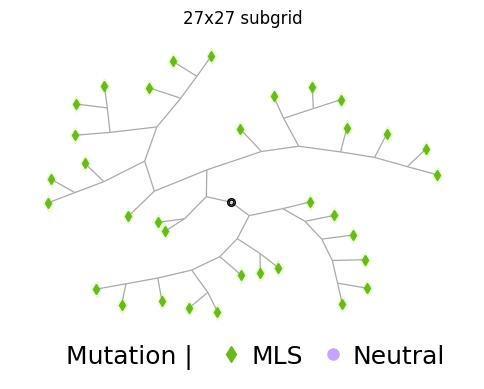

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/edge-color=darkgray+layout=radial+pop_size=81x81+root_id=11534188+viz=tree+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/edge-color=darkgray+layout=radial+pop_size=81x81+root_id=11534188+viz=tree+ext=.png


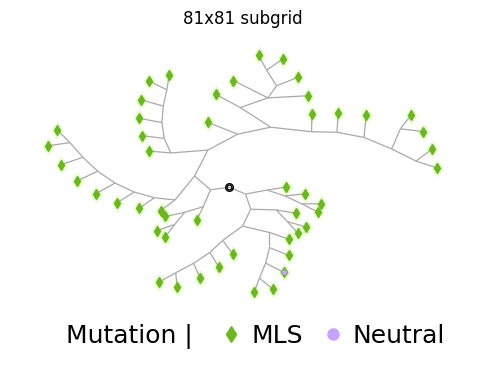

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/edge-color=darkgray+layout=radial+pop_size=243x243+root_id=16269365+viz=tree+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/edge-color=darkgray+layout=radial+pop_size=243x243+root_id=16269365+viz=tree+ext=.png


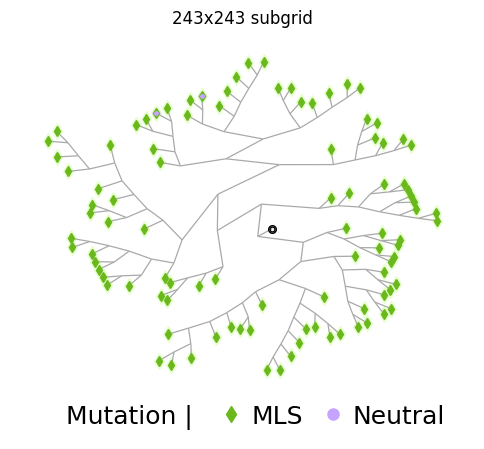

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/edge-color=darkgray+layout=radial+pop_size=1170x755+root_id=5418694+viz=tree+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/edge-color=darkgray+layout=radial+pop_size=1170x755+root_id=5418694+viz=tree+ext=.png


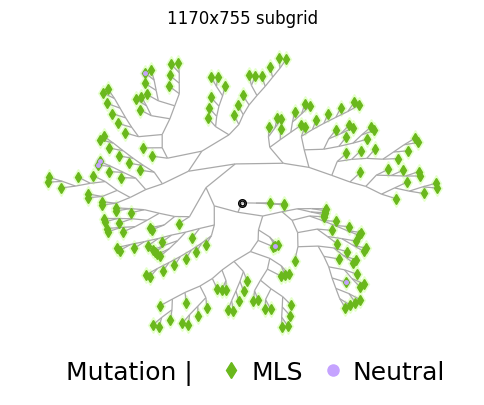

In [ ]:
_focal_mask = np.uint64(sum(1 << site for site in focal_sites))
_trait_present = phylo["trait_present"].to_numpy(dtype=np.uint64)
_is_leaf = phylo["is_leaf"].to_numpy()
_phylo = phylo.assign(
    has_mls=np.where(
        _is_leaf, (_trait_present & _focal_mask) != 0, np.nan
    ),
    has_neutral=np.where(
        _is_leaf, (_trait_present & ~_focal_mask) != 0, np.nan
    ),
)
_roots = _phylo.loc[_phylo["is_root"], ["id", "num_leaves", "pop_code"]]
_roots = _roots[_roots["num_leaves"] <= MAX_TREE_LEAVES]
_rng = random.Random(SEED)
for _pop_size in pop_size_order:
    _pops = populations.loc[
        populations["is_full_size"]
        & (populations["pop_size"] == _pop_size)
        & populations["pop_code"].isin(_roots["pop_code"]),
        "pop_code",
    ].tolist()
    if not _pops:
        continue
    _pop_code = _rng.choice(_pops)
    _root_id = (
        _roots.loc[_roots["pop_code"] == _pop_code]
        .nlargest(1, "num_leaves")["id"]
        .item()
    )

    _subtree = (
        _phylo[_phylo["root_id"] == _root_id]
        .pipe(pfl.alifestd_assign_contiguous_ids)
        .pipe(pfl.alifestd_try_add_ancestor_list_col)
    )
    _tree = apc.alife_dataframe_to_dendropy_tree(
        _subtree,
        setattrs=["has_mls", "has_neutral"],
    )
    with hstrat_aux.RngStateContext(6):
        _tree.ladderize()
        _tree.reorder(key=lambda *args: max(random.random(), 0.89))

    with tp.teed(
        ipx.plotting.tree,
        _tree,
        aspect=0.7,
        edge_color="darkgray",
        edge_linewidth=0.9,
        ladderize=True,
        layout="radial",
        layout_angular=True,
        layout_start=0.25,
        margins=0,
        teeplot_outattrs={"pop_size": _pop_size, "root_id": _root_id},
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _teed:
        plt.gcf().set_size_inches(6, 6)

        for _n, (_x, _y) in _teed.get_layout().T.items():
            _x_, _y_ = _x * np.cos(_y), _x * np.sin(_y)
            if _n.has_mls == 1.0:
                plt.plot(
                    _x_,
                    _y_,
                    "d",
                    markersize=8,
                    color="#E2FFC4",
                    alpha=0.8,
                    zorder=0,
                )
                plt.plot(
                    _x_,
                    _y_,
                    "d",
                    markersize=5,
                    color="#6AB81C",
                    alpha=1,
                    zorder=2,
                )
            if _n.has_neutral == 1.0:
                plt.plot(
                    _x_,
                    _y_,
                    "o",
                    markersize=5,
                    color="#C5A3FF",
                    alpha=0.3,
                    zorder=1,
                )
                plt.plot(
                    _x_,
                    _y_,
                    "o",
                    markersize=2.5,
                    color="#C5A3FF",
                    alpha=1.0,
                    zorder=3,
                )
            if _n is _tree.seed_node:
                for _size in 3.5, 5.5:
                    plt.plot(
                        _x_,
                        _y_,
                        "o",
                        markersize=_size,
                        color="black",
                        alpha=1,
                        fillstyle="none",
                    )

        plt.gca().margins(x=0.02, y=0.02)
        plt.title(f"{_pop_size} subgrid")

        (_h0,) = plt.plot(
            [], [], "d", markersize=0, color="#FFFFFF", label="Mutation | "
        )
        (_h1,) = plt.plot(
            [], [], "d", markersize=8, color="#6AB81C", label="MLS"
        )
        (_h2,) = plt.plot(
            [], [], "o", markersize=8, color="#C5A3FF", label="Neutral"
        )
        plt.legend(
            handles=[_h0, _h1, _h2],
            loc="upper center",
            bbox_to_anchor=(0.48, 0.05),
            frameon=False,
            ncol=4,
            fontsize=18,
            columnspacing=0.2,
            handletextpad=-0.2,
        )
    plt.close("all")

## Screen Mutation-defined Clades

MDCs are identified for each of the 16 trait sites by Fitch maximum parsimony over leaf states (root state assumed absent), as in `2026-10-15-mls-strong-fossils`.
Because each population's trees share no nodes with other populations', one screen over the whole forest is equivalent to screening each population separately.

The screen uses phyloframe's `alifestd_screen_trait_defined_clades_fitch_asexual`, which requires phyloframe >= 0.12.2 to run in linear time at this data size.

MDC size is measured as `carriers`, the number of descendant fossil genomes carrying the mutation; `num_genomes` counts all descendant fossil genomes.
`carrier_frac` is the carrier fraction among descendant genomes, and `is_terminal` marks MDCs arising on a terminal branch to a single genome (MDC node is an uncollapsed leaf).
`clade_duration` spans from MDC origin to its latest descendant fossil.

In [ ]:
_work = phylo[["id", "ancestor_id"]].copy()
_is_leaf = phylo["is_leaf"].to_numpy()
_clade_size = phylo["clade_size"].fillna(0).to_numpy(dtype=np.int64)
_trait_present = phylo["trait_present"].to_numpy(dtype=np.uint64)
mdc_ids = {}
mdc_carriers = {}
for _site in mo.status.progress_bar(range(NUM_SITES)):
    _has = ((_trait_present >> np.uint64(_site)) & np.uint64(1)) != 0
    _mask = _work.pipe(
        pfl.alifestd_screen_trait_defined_clades_fitch_asexual,
        mutate=True,
        mask_trait_absent=_is_leaf & ~_has,
        mask_trait_present=_is_leaf & _has,
    ).astype(bool)
    # passing counts rather than a mask sums carriers over descendants
    _carriers = _work.pipe(
        pfl.alifestd_calc_clade_trait_count_asexual,
        mutate=True,
        trait_mask=np.where(_is_leaf & _has, _clade_size, 0),
    )
    mdc_ids[_site] = np.flatnonzero(_mask)
    mdc_carriers[_site] = _carriers[_mask]

In [ ]:
_cols = [
    "id",
    "origin_time",
    "num_genomes",
    "clade_duration",
    "is_leaf",
    "clade_size",
    "pop_code",
]
mdcs = pd.concat(
    [
        phylo.loc[ids, _cols].assign(
            site=site,
            is_focal=site in focal_sites,
            is_control=site in control_sites,
            carriers=mdc_carriers[site],
        )
        for site, ids in mdc_ids.items()
    ],
    ignore_index=True,
)
mdcs["is_terminal"] = mdcs["is_leaf"] & (mdcs["clade_size"] == 1)
mdcs["carrier_frac"] = mdcs["carriers"] / mdcs["num_genomes"]
mdcs["effect_size"] = mdcs["site"].map(site_effect_sizes)
mdcs["mutation"] = np.where(
    mdcs["is_focal"],
    mdcs["effect_size"].map("s={:g}".format),
    "Neutral",
)
mdcs = mdcs.drop(columns=["is_leaf", "clade_size"]).merge(
    populations[["pop_code", "pop_size", "pop_tiles"]], on="pop_code"
)
mdcs.groupby(["pop_size", "mutation"], sort=False).agg(
    num_mdcs=("id", "size"),
    carriers_mean=("carriers", "mean"),
    carriers_singleton_frac=("carriers", lambda x: (x == 1).mean()),
    carrier_frac_mean=("carrier_frac", "mean"),
    terminal_frac=("is_terminal", "mean"),
    clade_duration_mean=("clade_duration", "mean"),
).unstack("pop_size")

num_mdcs carriers_mean carriers_singleton_frac ... carrier_frac_mean terminal_frac clade_duration_mean pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 ... 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 mutation Neutral 42238.0 38975.0 35777.0 27720.0 1.580165 1.617832 1.564105 1.474784 0.693570 0.678948 ... 0.997764 0.996854 0.693570 0.678948 0.693127 0.720707 884.232019 958.664375 905.501859 813.346465 s=1 NaN NaN 1.0 NaN NaN NaN 30.000000 NaN NaN NaN ... 1.000000 NaN NaN NaN 0.000000 NaN NaN NaN 7597.000000 NaN s=0.5 313240.0 344449.0 287883.0 196243.0 3.337489 2.316967 2.555069 2.824697 0.575054 0.580620 ... 0.930789 0.928519 0.575054 0.580620 0.578669 0.578319 1999.168328 1962.696939 2007.429452 2078.153223 s=0.25 22509.0 20600.0 18824.0 13440.0 1.005731 1.006019 1.005312 1.006027 0.994269 0.993981 ... 0.998845 0.998548 0.994269 0.993981 0.994741 0.994048 18.611578 20.924563 18.520878 23.514583 s=0.1 2794.0 2659.0 2406.0 1663.0 1.008232 1.006393 1.005819 1.007216 0.992126 0.993983 ... 0.999404 1.000000 0.992126 0.993983 0.994181 0.992784 6.390838 7.820233 9.673732 3.605532 s=0.05 2338.0 2171.0 1925.0 1381.0 1.033362 1.045140 1.059221 1.040550 0.973054 0.957163 ... 0.999169 1.000000 0.973054 0.957163 0.949610 0.962346 37.727545 62.749424 80.958961 47.700941 s=0.025 3008.0 2740.0 2646.0 1954.0 1.164561 1.167883 1.162887 1.136131 0.878657 0.879927 ... 0.998625 0.998216 0.878657 0.879927 0.885488 0.897134 259.557513 259.075547 261.498110 236.496418 s=0.01 3928.0 3540.0 3240.0 2417.0 1.373727 1.386158 1.381173 1.292925 0.772912 0.771751 ... 0.998811 0.997869 0.772912 0.771751 0.766667 0.805544 580.511965 601.225424 590.091358 511.891601 s=0.005 4471.0 4166.0 3776.0 2799.0 1.442630 1.484398 1.426112 1.390854 0.745247 0.732117 ... 0.998395 0.996816 0.745247 0.732117 0.745763 0.764916 693.617312 751.508641 706.628972 649.555556 9 rows × 24 columns

In [ ]:
mutation_order = [
    f"s={s:g}" for s in sorted(site_effect_sizes.unique(), reverse=True)
] + ["Neutral"]

## Mutation-frequency Screen

Within each population, baseline rate $\lambda$ is the mean MDC count per background (neutral) site.
Site significance is the Poisson survival probability of observing at least the site's MDC count under $\mathsf{Pois}(\lambda)$.
Neutral control sites are screened the same way, against the mean over the other background sites.
Populations with no background MDCs ($\lambda = 0$) are not screened.

In [ ]:
_pops = populations.loc[populations["is_full_size"], "pop_code"]
_counts = (
    mdcs.groupby(["pop_code", "site"])
    .size()
    .unstack("site")
    .reindex(index=_pops, columns=range(NUM_SITES))
    .fillna(0)
)
_bg_sum = _counts[background_sites].sum(axis=1)
_num_bg = len(background_sites)
_records = []
for _site in [*focal_sites, *control_sites]:
    _is_control = _site in control_sites
    _lam = (
        (_bg_sum - _counts[_site]) / (_num_bg - 1)
        if _is_control
        else _bg_sum / _num_bg
    )
    _k = _counts[_site]
    _records.append(
        pd.DataFrame(
            {
                "pop_code": _counts.index,
                "site": _site,
                "is_control": _is_control,
                "mdc_count": _k.to_numpy(),
                "lambda": _lam.to_numpy(),
                "fold_enrichment": (_k / _lam).to_numpy(),
                "poisson_sf_p": np.where(
                    _lam > 0, scipy_stats.poisson.sf(_k - 1, _lam), np.nan
                ),
            },
        ),
    )
freq_screen = pd.concat(_records, ignore_index=True).merge(
    populations[["pop_code", "pop_size", "pop_tiles"]], on="pop_code"
)
freq_screen["mutation"] = np.where(
    freq_screen["is_control"],
    "Neutral",
    freq_screen["site"].map(site_effect_sizes).map("s={:g}".format),
)
freq_screen["detected"] = freq_screen["poisson_sf_p"] < ALPHA
freq_screen.groupby(["pop_size", "mutation"], sort=False).agg(
    num_populations=("pop_code", "nunique"),
    mdc_count_mean=("mdc_count", "mean"),
    lambda_mean=("lambda", "mean"),
    fold_enrichment_median=("fold_enrichment", "median"),
    detection_rate=("detected", "mean"),
).unstack("pop_size")

num_populations mdc_count_mean lambda_mean fold_enrichment_median detection_rate pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 mutation s=1 1 1161 126 12 0.00 0.000000 0.007937 0.000000 5279.75 4.196275 35.493056 288.75 0.000000 0.000000 0.000000 0.000000 0.000 0.000000 0.000000 0.00000 s=0.5 1 1161 126 12 313240.00 296.683032 2284.785714 16353.583333 5279.75 4.196275 35.493056 288.75 59.328567 71.250000 64.723987 56.897573 1.000 1.000000 1.000000 1.00000 s=0.25 1 1161 126 12 22509.00 17.743325 149.396825 1120.000000 5279.75 4.196275 35.493056 288.75 4.263270 4.222222 4.232730 3.863158 1.000 0.987941 1.000000 1.00000 s=0.1 1 1161 126 12 2794.00 2.290267 19.095238 138.583333 5279.75 4.196275 35.493056 288.75 0.529192 0.516129 0.531405 0.494936 0.000 0.000861 0.000000 0.00000 s=0.05 1 1161 126 12 2338.00 1.869940 15.277778 115.083333 5279.75 4.196275 35.493056 288.75 0.442824 0.432432 0.419528 0.404963 0.000 0.000861 0.000000 0.00000 s=0.025 1 1161 126 12 3008.00 2.360034 21.000000 162.833333 5279.75 4.196275 35.493056 288.75 0.569724 0.516129 0.576160 0.549512 0.000 0.004307 0.000000 0.00000 s=0.01 1 1161 126 12 3928.00 3.049096 25.714286 201.416667 5279.75 4.196275 35.493056 288.75 0.743975 0.705882 0.716590 0.698736 0.000 0.006891 0.000000 0.00000 s=0.005 1 1161 126 12 4471.00 3.588286 29.968254 233.250000 5279.75 4.196275 35.493056 288.75 0.846820 0.827586 0.847199 0.801366 0.000 0.017227 0.000000 0.00000 Neutral 1 1161 126 12 5279.75 4.196275 35.493056 288.750000 5279.75 4.196275 35.493056 288.75 0.998976 0.965517 1.004159 0.986629 0.125 0.045004 0.056548 0.09375

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/estimator=median+hue=pop-size+viz=pointplot+x=mutation+y=fold-enrichment+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/estimator=median+hue=pop-size+viz=pointplot+x=mutation+y=fold-enrichment+ext=.png


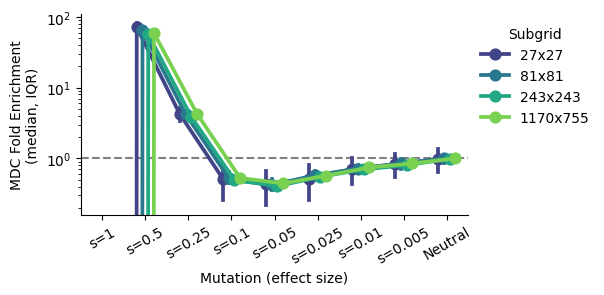

In [ ]:
with tp.teed(
    sns.pointplot,
    data=freq_screen.replace([np.inf, -np.inf], np.nan),
    x="mutation",
    y="fold_enrichment",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    estimator="median",
    errorbar=("pi", 50),
    dodge=0.4,
    teeplot_outexclude=["palette", "hue_order", "dodge", "order"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _ax:
    _ax.axhline(1, color="gray", linestyle="--", zorder=0)
    _ax.set_yscale("log")
    _ax.set_xlabel("Mutation (effect size)")
    _ax.set_ylabel("MDC Fold Enrichment\n(median, IQR)")
    _ax.tick_params(axis="x", rotation=30)
    sns.move_legend(
        _ax,
        "upper left",
        bbox_to_anchor=(1, 1),
        title="Subgrid",
        frameon=False,
    )
    sns.despine(ax=_ax)
    _ax.figure.set_size_inches(5, 2.6)

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/hue=pop-size+viz=pointplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/hue=pop-size+viz=pointplot+x=mutation+y=detected+ext=.png


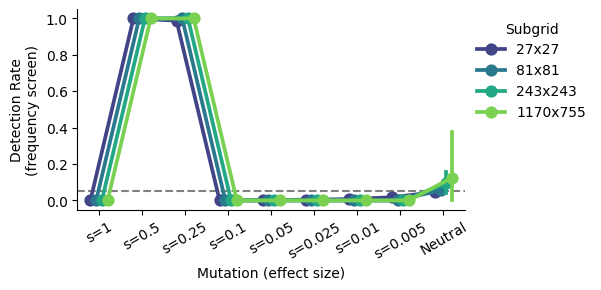

In [ ]:
with tp.teed(
    sns.pointplot,
    data=freq_screen.astype({"detected": float}),
    x="mutation",
    y="detected",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    errorbar=("ci", 95),
    n_boot=1000,
    seed=SEED,
    dodge=0.4,
    teeplot_outexclude=["palette", "hue_order", "dodge", "order", "seed"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _ax:
    _ax.axhline(ALPHA, color="gray", linestyle="--", zorder=0)
    _ax.set_ylim(-0.05, 1.05)
    _ax.set_xlabel("Mutation (effect size)")
    _ax.set_ylabel("Detection Rate\n(frequency screen)")
    _ax.tick_params(axis="x", rotation=30)
    sns.move_legend(
        _ax,
        "upper left",
        bbox_to_anchor=(1, 1),
        title="Subgrid",
        frameon=False,
    )
    sns.despine(ax=_ax)
    _ax.figure.set_size_inches(5, 2.6)

## Clade-fitness Screen

Within each population, each MDC's size (`carriers`) and clade duration are percentile-ranked (mean rank for ties) against comparator MDCs: the pooled MDCs of background (neutral) sites in the same population, drawn from the same MDC subset.
Under the `epoch100` normalization, comparison is further restricted to comparators originating within the same 100-update `origin_time` bin, controlling for recency bias.

For each population and site, a one-sided Mann-Whitney U test asks whether the site's MDC percentiles are lower than those of background MDCs (excluding the site itself, for neutral control sites).
MLS predicts lower percentiles.

MDC subsets are `all` MDCs, `inner` (excluding terminal-branch MDCs), and `inner_f75` (non-terminal MDCs with at least 75% carriers).

In [ ]:
subsets = {
    "all": lambda df: np.ones(len(df), dtype=bool),
    "inner": lambda df: ~df["is_terminal"].to_numpy(),
    "inner_f75": lambda df: (
        ~df["is_terminal"].to_numpy()
        & (df["carrier_frac"].to_numpy() >= 0.75)
    ),
}

In [ ]:
normalizations = {"all": None, "epoch100": 100}
stat_cols = ("carriers", "clade_duration")
_parts = []
for _subset, _subset_mask in subsets.items():
    _data = mdcs[_subset_mask(mdcs)]
    _comparator = ~_data["is_focal"].to_numpy()
    _keep = ~_comparator | _data["is_control"].to_numpy()
    for _norm, _binwidth in normalizations.items():
        _epoch = (
            np.zeros(len(_data), dtype=np.int64)
            if _binwidth is None
            else (_data["origin_time"].to_numpy() // _binwidth).astype(
                np.int64
            )
        )
        _groups = _data["pop_code"].to_numpy() * 2**16 + _epoch
        for _stat in stat_cols:
            _parts.append(
                _data[
                    ["pop_code", "site", "is_focal", "is_control"]
                ].assign(
                    subset=_subset,
                    normalization=_norm,
                    stat=_stat,
                    percentile=percentileofscore_grouped(
                        _data[_stat].to_numpy(dtype=float),
                        _groups,
                        _comparator,
                    ),
                ),
            )
normed = pd.concat(_parts, ignore_index=True).dropna(subset=["percentile"])

In [ ]:
_records = []
_tested_sites = [*focal_sites, *control_sites]
for (_pop, _subset, _norm, _stat), _group in mo.status.progress_bar(
    normed.groupby(
        ["pop_code", "subset", "normalization", "stat"], sort=False
    ),
):
    _sites = _group["site"].to_numpy()
    _pct = _group["percentile"].to_numpy()
    _is_bg = ~_group["is_focal"].to_numpy()
    for _site in _tested_sites:
        _in_site = _sites == _site
        _x = _pct[_in_site]
        _y = _pct[_is_bg & ~_in_site]
        if not len(_x) or not len(_y):
            continue
        _mw_u, _mw_p = scipy_stats.mannwhitneyu(_x, _y, alternative="less")
        _records.append(
            {
                "pop_code": _pop,
                "subset": _subset,
                "normalization": _norm,
                "stat": _stat,
                "site": _site,
                "n_site": len(_x),
                "n_background": len(_y),
                "site_mean_pct": _x.mean(),
                "p_mw_less": _mw_p,
                "cliffs_delta": 2 * _mw_u / (len(_x) * len(_y)) - 1,
            },
        )
fitness_screen = pd.DataFrame(_records)

In [ ]:
# one row per screened (population, site), including those with no MDCs
# in subset, which count as not detected
_pop_sites = freq_screen[["pop_code", "site", "mutation"]]
fitness_detection = (
    fitness_screen[["subset", "normalization", "stat"]]
    .drop_duplicates()
    .merge(_pop_sites, how="cross")
    .merge(
        fitness_screen,
        on=["pop_code", "site", "subset", "normalization", "stat"],
        how="left",
    )
    .merge(populations[["pop_code", "pop_size", "pop_tiles"]])
)
fitness_detection["is_control"] = fitness_detection["site"].isin(
    control_sites
)
fitness_detection["detected"] = fitness_detection["p_mw_less"] < ALPHA
fitness_detection.groupby(
    ["subset", "normalization", "stat", "pop_size", "mutation"],
    sort=False,
).agg(
    num_populations=("pop_code", "nunique"),
    num_screened=("p_mw_less", "count"),
    n_site_mean=("n_site", "mean"),
    site_mean_pct_mean=("site_mean_pct", "mean"),
    cliffs_delta_mean=("cliffs_delta", "mean"),
    detection_rate=("detected", "mean"),
).unstack(
    "pop_size"
)

num_populations num_screened n_site_mean ... site_mean_pct_mean cliffs_delta_mean detection_rate pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 ... 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 subset normalization stat mutation all all carriers s=1 1 1161 126 12 0 0 1 0 NaN NaN ... 100.000000 NaN NaN NaN 1.000000 NaN 0.00 0.000000 0.000000 0.000000 s=0.5 1 1161 126 12 1 1161 126 12 313240.000 296.683032 ... 57.606218 59.261057 0.162825 0.129794 0.152124 0.185221 0.00 0.000861 0.000000 0.000000 s=0.25 1 1161 126 12 1 1161 126 12 22509.000 17.743325 ... 34.879523 36.300531 -0.301513 -0.315537 -0.302410 -0.273989 1.00 0.956934 1.000000 1.000000 s=0.1 1 1161 126 12 1 1064 126 12 2794.000 2.499060 ... 34.896744 36.353796 -0.299589 -0.315977 -0.302065 -0.272924 1.00 0.034453 0.992063 1.000000 s=0.05 1 1161 126 12 1 967 126 12 2338.000 2.245088 ... 37.058472 37.775152 -0.281949 -0.288781 -0.258831 -0.244497 1.00 0.010336 0.809524 1.000000 ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... inner_f75 epoch100 clade_duration s=0.05 1 1161 126 12 1 14 57 12 59.000 1.000000 ... 18.055556 18.232936 -0.535770 -0.285714 -0.642592 -0.637560 1.00 0.006891 0.309524 0.916667 s=0.025 1 1161 126 12 1 56 102 12 351.000 1.035714 ... 33.997179 38.504008 -0.315259 -0.389610 -0.323119 -0.231595 1.00 0.024978 0.341270 0.333333 s=0.01 1 1161 126 12 1 151 126 12 871.000 1.072848 ... 42.440559 42.975571 -0.127897 -0.195728 -0.149557 -0.141530 1.00 0.054264 0.269841 0.500000 s=0.005 1 1161 126 12 1 195 126 12 1106.000 1.092308 ... 45.724109 46.870029 -0.069962 -0.066480 -0.086641 -0.062921 1.00 0.072351 0.222222 0.083333 Neutral 1 1161 126 12 8 6812 1008 96 1573.125 1.822813 ... 50.004450 49.974025 -0.000269 0.002176 0.000160 -0.000513 0.25 0.022610 0.041667 0.083333 108 rows × 24 columns

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/col=stat+estimator=median+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=site-mean-pct+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/col=stat+estimator=median+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=site-mean-pct+ext=.png


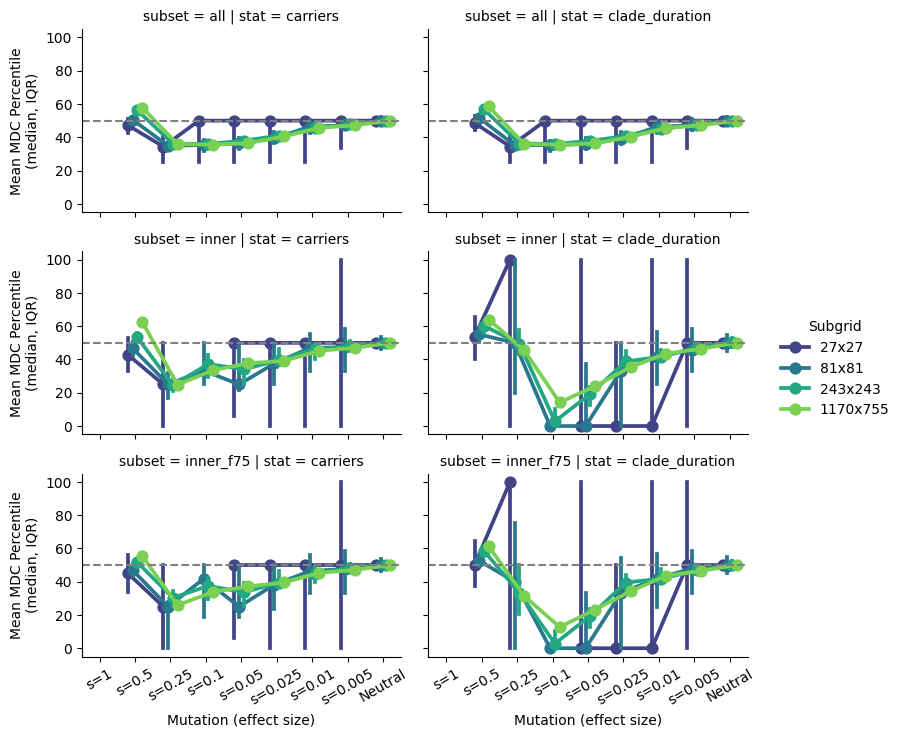

In [ ]:
with tp.teed(
    sns.catplot,
    data=fitness_detection[
        fitness_detection["normalization"] == "epoch100"
    ].dropna(subset=["site_mean_pct"]),
    x="mutation",
    y="site_mean_pct",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    col="stat",
    row="subset",
    kind="point",
    estimator="median",
    errorbar=("pi", 50),
    dodge=0.4,
    height=2.4,
    aspect=1.6,
    teeplot_outattrs={"normalization": "epoch100"},
    teeplot_outexclude=["palette", "hue_order", "dodge", "order"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    _g.refline(y=50, color="gray", linestyle="--")
    _g.set_axis_labels(
        "Mutation (effect size)", "Mean MDC Percentile\n(median, IQR)"
    )
    _g.tick_params(axis="x", rotation=30)
    _g.legend.set_title("Subgrid")

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/col=stat+hue=pop-size+kind=point+normalization=all+row=subset+viz=catplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/col=stat+hue=pop-size+kind=point+normalization=all+row=subset+viz=catplot+x=mutation+y=detected+ext=.png


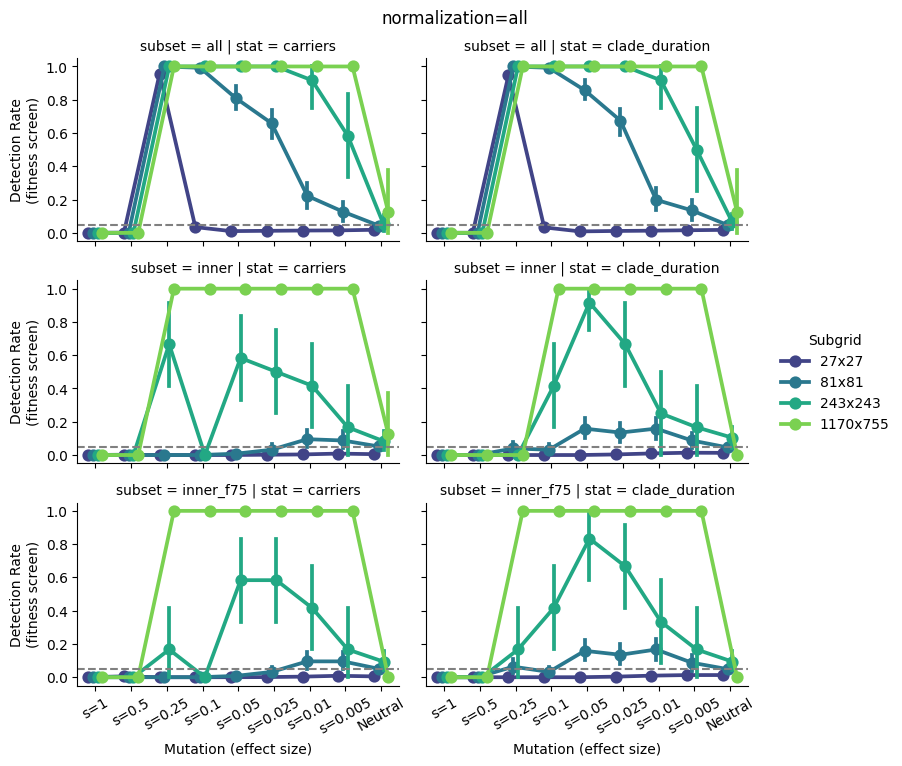

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/col=stat+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/col=stat+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=detected+ext=.png


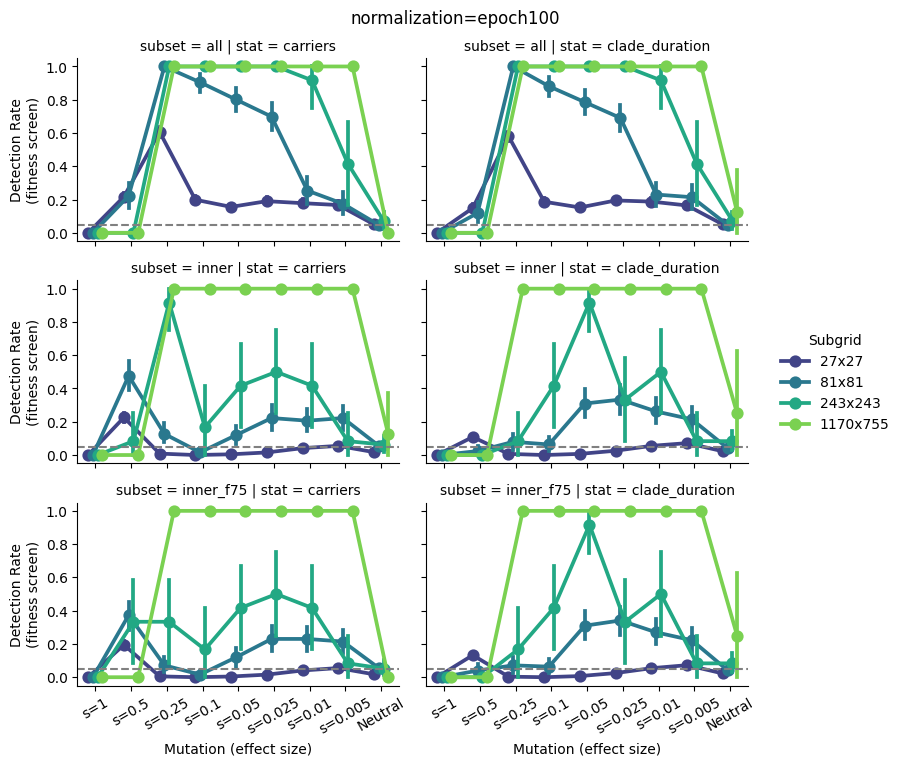

In [ ]:
for _norm in "all", "epoch100":
    with tp.teed(
        sns.catplot,
        data=fitness_detection[
            fitness_detection["normalization"] == _norm
        ].astype({"detected": float}),
        x="mutation",
        y="detected",
        order=mutation_order,
        hue="pop_size",
        hue_order=pop_size_order,
        palette="viridis",
        col="stat",
        row="subset",
        kind="point",
        errorbar=("ci", 95),
        n_boot=1000,
        seed=SEED,
        dodge=0.4,
        height=2.4,
        aspect=1.6,
        teeplot_outattrs={"normalization": _norm},
        teeplot_outexclude=[
            "palette",
            "hue_order",
            "dodge",
            "order",
            "seed",
        ],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        _g.refline(y=ALPHA, color="gray", linestyle="--")
        _g.set(ylim=(-0.05, 1.05))
        _g.set_axis_labels(
            "Mutation (effect size)", "Detection Rate\n(fitness screen)"
        )
        _g.tick_params(axis="x", rotation=30)
        _g.legend.set_title("Subgrid")
        _g.figure.suptitle(f"normalization={_norm}", y=1.02)
    plt.close("all")

In [ ]:
mo.md(f"""
## Detectability Summary

Fraction of populations in which each screen detects each site at $\\alpha = {ALPHA}$, by population size (rows) and effect size (columns).
The `Neutral` column gives the false positive rate over neutral control sites, and should sit near {ALPHA}.
Fitness screens shown use `epoch100` normalization.

Note that sampled fossil genomes per population grow with subgrid size (fossils were sampled with an equal budget per fossil layer and subgrid), so population size and sample size are confounded here.
The full grid is a single population, so its detection rates are each 0 or 1.
""")

## Detectability Summary

Fraction of populations in which each screen detects each site at $\alpha = 0.05$, by population size (rows) and effect size (columns).
The `Neutral` column gives the false positive rate over neutral control sites, and should sit near 0.05.
Fitness screens shown use `epoch100` normalization.

Note that sampled fossil genomes per population grow with subgrid size (fossils were sampled with an equal budget per fossil layer and subgrid), so population size and sample size are confounded here.
The full grid is a single population, so its detection rates are each 0 or 1.

In [ ]:
_screens = {
    "frequency": freq_screen,
    **{
        f"fitness {_stat} {_subset}": fitness_detection[
            (fitness_detection["normalization"] == "epoch100")
            & (fitness_detection["stat"] == _stat)
            & (fitness_detection["subset"] == _subset)
        ]
        for _stat in ("carriers", "clade_duration")
        for _subset in ("all", "inner_f75")
    },
}
detectability = pd.concat(
    [
        _df.groupby(["pop_size", "mutation"], as_index=False)
        .agg(
            detection_rate=("detected", "mean"),
            num_screened=("detected", "size"),
        )
        .assign(screen=_screen)
        for _screen, _df in _screens.items()
    ],
    ignore_index=True,
)
detectability.pivot_table(
    index=["screen", "pop_size"],
    columns="mutation",
    values="detection_rate",
    sort=False,
)

mutation Neutral s=0.005 s=0.01 s=0.025 s=0.05 s=0.1 s=0.25 s=0.5 s=1 screen pop_size frequency 1170x755 0.125000 0.000000 0.000000 0.000000 0.000000 0.000000 1.000000 1.000000 0.0 243x243 0.093750 0.000000 0.000000 0.000000 0.000000 0.000000 1.000000 1.000000 0.0 27x27 0.045004 0.017227 0.006891 0.004307 0.000861 0.000861 0.987941 1.000000 0.0 81x81 0.056548 0.000000 0.000000 0.000000 0.000000 0.000000 1.000000 1.000000 0.0 fitness carriers all 1170x755 0.000000 1.000000 1.000000 1.000000 1.000000 1.000000 1.000000 0.000000 0.0 ... ... ... ... ... ... ... ... ... ... ... fitness clade_duration all 81x81 0.047619 0.214286 0.230159 0.690476 0.785714 0.880952 1.000000 0.119048 0.0 fitness clade_duration inner_f75 1170x755 0.250000 1.000000 1.000000 1.000000 1.000000 1.000000 1.000000 0.000000 0.0 243x243 0.083333 0.083333 0.500000 0.333333 0.916667 0.416667 0.166667 0.000000 0.0 27x27 0.022610 0.072351 0.054264 0.024978 0.006891 0.000000 0.003445 0.132644 0.0 81x81 0.041667 0.222222 0.269841 0.341270 0.309524 0.063492 0.071429 0.039683 0.0 20 rows × 9 columns

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/screen=frequency+viz=heatmap+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/screen=frequency+viz=heatmap+ext=.png


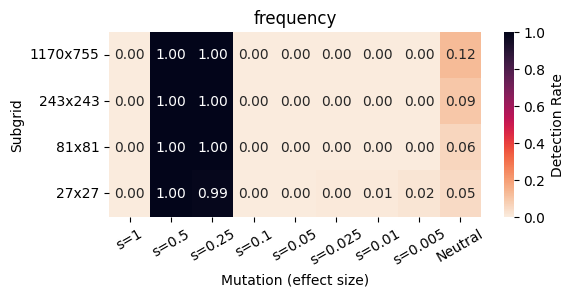

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/screen=fitness-carriers-all+viz=heatmap+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/screen=fitness-carriers-all+viz=heatmap+ext=.png


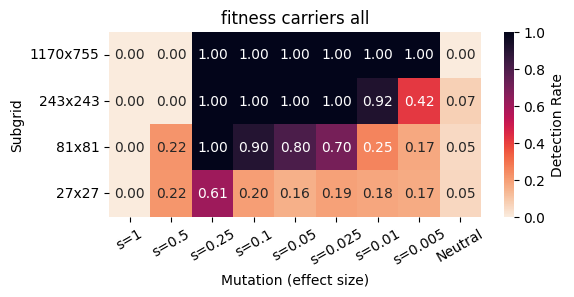

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/screen=fitness-carriers-inner_f75+viz=heatmap+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/screen=fitness-carriers-inner_f75+viz=heatmap+ext=.png


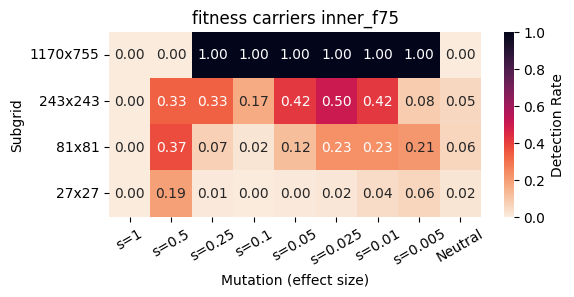

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/screen=fitness-clade_duration-all+viz=heatmap+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/screen=fitness-clade_duration-all+viz=heatmap+ext=.png


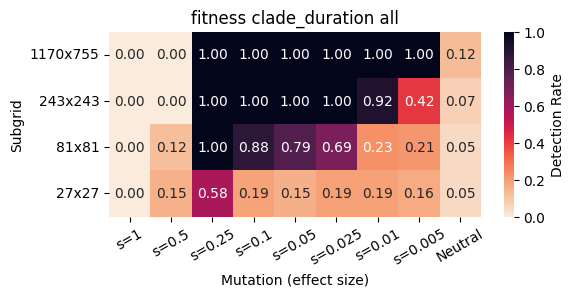

teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/screen=fitness-clade_duration-inner_f75+viz=heatmap+ext=.pdf
teeplots/2026-10-19-mls-indiv-ratematched-fossils-reservoir/screen=fitness-clade_duration-inner_f75+viz=heatmap+ext=.png


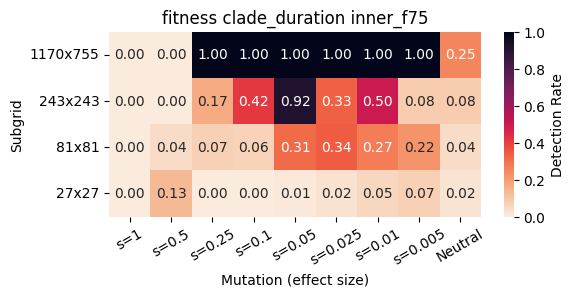

In [ ]:
for _screen, _df in detectability.groupby("screen", sort=False):
    _pivot = _df.pivot(
        index="pop_size", columns="mutation", values="detection_rate"
    ).reindex(index=pop_size_order[::-1], columns=mutation_order)
    with tp.teed(
        sns.heatmap,
        _pivot,
        annot=True,
        fmt=".2f",
        cmap="rocket_r",
        vmin=0,
        vmax=1,
        cbar_kws={"label": "Detection Rate"},
        teeplot_outattrs={"screen": _screen.replace(" ", "-")},
        teeplot_outexclude=["annot", "fmt", "cmap", "vmin", "vmax"],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _ax:
        _ax.set_xlabel("Mutation (effect size)")
        _ax.set_ylabel("Subgrid")
        _ax.set_title(_screen)
        _ax.tick_params(axis="x", rotation=30)
        _ax.tick_params(axis="y", rotation=0)
        _ax.figure.set_size_inches(6, 2.4)
    plt.close("all")